In [3]:
# ==============================================================================
# Cell 1: Setup & Load Feature Definitions from 'NUSW-NB15_features.csv'
# ==============================================================================
import os
import glob
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# 1. Robust path detection (works whether kernel runs from root or ml/notebooks)
if os.path.exists("../data/raw/UNSW-NB15"):
    DATA_DIR = "../data/raw/UNSW-NB15"
    OUTPUT_DIR = "../data/interim/UNSW-NB15"
    REPORT_DIR = "../data/reports/UNSW-NB15"
else:
    DATA_DIR = "ml/data/raw/UNSW-NB15"
    OUTPUT_DIR = "ml/data/interim/UNSW-NB15"
    REPORT_DIR = "ml/data/reports/UNSW-NB15"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# 2. Load feature definitions (cp1252 handles byte 0x92 properly)
FEAT_FILE = os.path.join(DATA_DIR, "NUSW-NB15_features.csv")
df_features = pd.read_csv(FEAT_FILE, encoding='cp1252')

# 3. FIX: Strip trailing whitespace from column headers (fixes 'Type ' -> 'Type')
df_features.columns = df_features.columns.str.strip()

# 4. FIX: Clean feature names (fixes 'ct_src_ ltm' -> 'ct_src_ltm')
df_features['Name'] = df_features['Name'].str.strip().str.replace(' ', '')
FEATURE_NAMES = df_features['Name'].tolist()

print(f"✅ Successfully loaded {len(FEATURE_NAMES)} features from {os.path.basename(FEAT_FILE)}")
print(f"First 5 features: {FEATURE_NAMES[:5]}")
print(f"Last 5 features : {FEATURE_NAMES[-5:]}\n")

# Display feature metadata table
display(df_features[['No.', 'Name', 'Type', 'Description']].head(10))


✅ Successfully loaded 49 features from NUSW-NB15_features.csv
First 5 features: ['srcip', 'sport', 'dstip', 'dsport', 'proto']
Last 5 features : ['ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'Label']



,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [4]:
# ==============================================================================
# Cell 2: Load UNSW-NB15 CSV Files (with Headers Applied)
# ==============================================================================
raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))
print(f"📁 Found {len(raw_files)} raw data files:\n" + "\n".join([f"  • {os.path.basename(f)}" for f in raw_files]))

def load_unsw_file(file_path, nrows=None):
    """
    Loads a UNSW-NB15 raw CSV file applying the 49 canonical feature column names.
    """
    return pd.read_csv(
        file_path,
        header=None,
        names=FEATURE_NAMES,
        nrows=nrows,
        low_memory=False,
        encoding='latin1'
    )

# ------------------------------------------------------------------------------
# Option A: Quick Preview (First 10,000 rows of File 1)
# ------------------------------------------------------------------------------
print(f"\n🚀 Loading sample from {os.path.basename(raw_files[0])}...")
df_sample = load_unsw_file(raw_files[0], nrows=10000)
print(f"Sample loaded: shape {df_sample.shape}")
display(df_sample[['proto', 'service', 'state', 'dur', 'sbytes', 'dbytes', 'attack_cat', 'Label']].head())

# ------------------------------------------------------------------------------
# Option B: Load All 4 Files into a Dictionary for Inspection
# ------------------------------------------------------------------------------
datasets = {}
total_records = 0

print("\n🚀 Loading all 4 files for inspection...")
t_start = time.time()

for fpath in raw_files:
    fname = os.path.basename(fpath)
    t0 = time.time()
    
    df_temp = load_unsw_file(fpath)
    datasets[fname] = df_temp
    total_records += len(df_temp)
    
    print(f"  • {fname}: {len(df_temp):,} rows ({time.time()-t0:.1f}s)")

print(f"\n🎉 Successfully loaded all files! Total flows: {total_records:,} in {time.time()-t_start:.1f}s")


📁 Found 4 raw data files:
  • UNSW-NB15_1.csv
  • UNSW-NB15_2.csv
  • UNSW-NB15_3.csv
  • UNSW-NB15_4.csv

🚀 Loading sample from UNSW-NB15_1.csv...
Sample loaded: shape (10000, 49)


,proto,service,state,dur,sbytes,dbytes,attack_cat,Label
0,udp,dns,CON,0.0011,132,164,NaN,0
1,udp,-,CON,0.0361,528,304,NaN,0
2,udp,dns,CON,0.0011,146,178,NaN,0
3,udp,dns,CON,0.0012,132,164,NaN,0
4,udp,dns,CON,0.0012,146,178,NaN,0



🚀 Loading all 4 files for inspection...
  • UNSW-NB15_1.csv: 700,001 rows (9.2s)
  • UNSW-NB15_2.csv: 700,001 rows (9.0s)
  • UNSW-NB15_3.csv: 700,001 rows (8.2s)
  • UNSW-NB15_4.csv: 440,044 rows (4.9s)

🎉 Successfully loaded all files! Total flows: 2,540,047 in 31.3s


In [5]:
# ==============================================================================
# Cell 2: Inspect File Sizes, Shapes, Rows, Columns & Basic Info
# ==============================================================================
import os
import glob
import time
import pandas as pd
import numpy as np

# Find raw CSV files
raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))
print(f"🔍 Found {len(raw_files)} data files in: {os.path.abspath(DATA_DIR)}\n")

file_summaries = []
total_disk_bytes = 0
total_mem_bytes = 0
total_dataset_rows = 0
total_attacks = 0
total_normals = 0

t_start = time.time()

for idx, fpath in enumerate(raw_files, 1):
    fname = os.path.basename(fpath)
    print(f"[{idx}/4] Analyzing {fname}...", end="", flush=True)
    t0 = time.time()
    
    # 1. Disk file size
    fsize_bytes = os.path.getsize(fpath)
    fsize_mb = fsize_bytes / (1024 * 1024)
    total_disk_bytes += fsize_bytes
    
    # 2. Read with canonical feature names
    df_temp = pd.read_csv(
        fpath,
        header=None,
        names=FEATURE_NAMES,
        low_memory=False,
        encoding='latin1'
    )
    
    rows, cols = df_temp.shape
    total_dataset_rows += rows
    
    # 3. In-memory footprint
    mem_bytes = df_temp.memory_usage(deep=True).sum()
    mem_mb = mem_bytes / (1024 * 1024)
    total_mem_bytes += mem_bytes
    
    # 4. Binary class balance
    n_normal = int((df_temp['Label'] == 0).sum())
    n_attack = int((df_temp['Label'] == 1).sum())
    total_normals += n_normal
    total_attacks += n_attack
    attack_ratio = (n_attack / rows * 100) if rows > 0 else 0
    
    file_summaries.append({
        'File Name': fname,
        'Disk Size (MB)': round(fsize_mb, 2),
        'Rows': rows,
        'Columns': cols,
        'RAM Usage (MB)': round(mem_mb, 2),
        'Normal (0)': n_normal,
        'Attack (1)': n_attack,
        'Attack %': round(attack_ratio, 2)
    })
    
    print(f" -> {rows:,} rows, {cols} cols ({time.time()-t0:.1f}s)")

# ------------------------------------------------------------------------------
# 5. Format & Display Summary Table
# ------------------------------------------------------------------------------
df_summary = pd.DataFrame(file_summaries)

# Append Grand Total Row
df_total = pd.DataFrame([{
    'File Name': '🔥 GRAND TOTAL',
    'Disk Size (MB)': round(total_disk_bytes / (1024 * 1024), 2),
    'Rows': total_dataset_rows,
    'Columns': cols,
    'RAM Usage (MB)': round(total_mem_bytes / (1024 * 1024), 2),
    'Normal (0)': total_normals,
    'Attack (1)': total_attacks,
    'Attack %': round(total_attacks / total_dataset_rows * 100, 2)
}])

df_full_summary = pd.concat([df_summary, df_total], ignore_index=True)

print("\n" + "="*85)
print("📊 UNSW-NB15 FILE SUMMARY & SHAPE INVENTORY")
print("="*85)
display(df_full_summary)


🔍 Found 4 data files in: c:\Users\himma\Desktop\Projects\AI project\SentinelAI\ml\data\raw\UNSW-NB15

[1/4] Analyzing UNSW-NB15_1.csv... -> 700,001 rows, 49 cols (9.1s)
[2/4] Analyzing UNSW-NB15_2.csv... -> 700,001 rows, 49 cols (9.3s)
[3/4] Analyzing UNSW-NB15_3.csv... -> 700,001 rows, 49 cols (8.4s)
[4/4] Analyzing UNSW-NB15_4.csv... -> 440,044 rows, 49 cols (5.2s)

📊 UNSW-NB15 FILE SUMMARY & SHAPE INVENTORY


,File Name,Disk Size (MB),Rows,Columns,RAM Usage (MB),Normal (0),Attack (1),Attack %
0,UNSW-NB15_1.csv,161.1500,700001,49,288.3100,677786,22215,3.1700
1,UNSW-NB15_2.csv,157.5700,700001,49,286.2400,647252,52749,7.5400
2,UNSW-NB15_3.csv,147.4300,700001,49,287.3900,542576,157425,22.4900
3,UNSW-NB15_4.csv,93.0700,440044,49,180.5700,351150,88894,20.2000
4,🔥 GRAND TOTAL,559.2100,2540047,49,1042.5000,2218764,321283,12.6500


In [6]:
# ==============================================================================
# Cell 3: Full Dataset Schema & Feature Types Breakdown
# ==============================================================================
# Use sample to inspect data types across the 49 columns
df_sample = pd.read_csv(raw_files[0], header=None, names=FEATURE_NAMES, nrows=5000, encoding='latin1')

print("📋 Feature Type Distribution:")
nominal_cols = ['srcip', 'dstip', 'proto', 'state', 'service']
target_cols = ['attack_cat', 'Label']
time_cols = ['Stime', 'Ltime']
numeric_cols = [c for c in FEATURE_NAMES if c not in nominal_cols + target_cols + time_cols]

print(f"  • Numeric Flow Metrics : {len(numeric_cols)} columns")
print(f"  • Categorical / Nominal: {len(nominal_cols)} columns {nominal_cols}")
print(f"  • Timestamps           : {len(time_cols)} columns {time_cols}")
print(f"  • Targets              : {len(target_cols)} columns {target_cols}")
print(f"  • Total Features       : {len(FEATURE_NAMES)} columns")

# Summary DataFrame of Columns
col_info = pd.DataFrame({
    'No': range(1, len(FEATURE_NAMES) + 1),
    'Feature': FEATURE_NAMES,
    'Inferred Dtype': [str(df_sample[c].dtype) for c in FEATURE_NAMES],
    'Sample Value': [str(df_sample[c].iloc[0]) for c in FEATURE_NAMES]
})

print("\n📄 First 20 Columns Preview:")
display(col_info.head(20))


📋 Feature Type Distribution:
  • Numeric Flow Metrics : 40 columns
  • Categorical / Nominal: 5 columns ['srcip', 'dstip', 'proto', 'state', 'service']
  • Timestamps           : 2 columns ['Stime', 'Ltime']
  • Targets              : 2 columns ['attack_cat', 'Label']
  • Total Features       : 49 columns

📄 First 20 Columns Preview:


,No,Feature,Inferred Dtype,Sample Value
0,1,srcip,str,ï»¿59.166.0.0
1,2,sport,int64,1390
2,3,dstip,str,149.171.126.6
3,4,dsport,str,53
4,5,proto,str,udp
5,6,state,str,CON
6,7,dur,float64,0.001055
7,8,sbytes,int64,132
8,9,dbytes,int64,164
9,10,sttl,int64,31


In [7]:
# ==============================================================================
# Cell 4: Deep Schema Consistency Audit Across All 4 Files
# ==============================================================================
import os
import glob
import pandas as pd
import numpy as np

raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))
print(f"🔍 Auditing Schema Consistency for {len(raw_files)} files...\n")

file_dtypes = {}
port_anomalies = {}
attack_classes = {}
null_counts_by_file = {}

for fpath in raw_files:
    fname = os.path.basename(fpath)
    df = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, low_memory=False, encoding='latin1')
    
    # 1. Record data types
    file_dtypes[fname] = df.dtypes.astype(str)
    
    # 2. Check non-numeric strings in sport and dsport (e.g., hex or '-')
    sport_str = df['sport'].astype(str)
    dsport_str = df['dsport'].astype(str)
    hex_sport = sport_str[sport_str.str.startswith('0x') | (sport_str == '-')].unique().tolist()
    hex_dsport = dsport_str[dsport_str.str.startswith('0x') | (dsport_str == '-')].unique().tolist()
    
    port_anomalies[fname] = {
        'sport dtype': str(df['sport'].dtype),
        'dsport dtype': str(df['dsport'].dtype),
        'sport hex/dash values': hex_sport if hex_sport else 'None (Clean int)',
        'dsport hex/dash values': hex_dsport if hex_dsport else 'None (Clean int)'
    }
    
    # 3. Record raw unique attack categories
    raw_cats = df['attack_cat'].dropna().unique().tolist()
    attack_classes[fname] = raw_cats

# ------------------------------------------------------------------------------
# Report 1: Data Type Inconsistency Across Files
# ------------------------------------------------------------------------------
df_all_dtypes = pd.DataFrame(file_dtypes)
# Filter only columns where dtypes differ across files
differing_dtypes = df_all_dtypes[df_all_dtypes.nunique(axis=1) > 1]

print("⚠️ Columns with Differing Inferred Data Types Across Files:")
if len(differing_dtypes) > 0:
    display(differing_dtypes)
else:
    print("✅ All columns have identical inferred data types.")

# ------------------------------------------------------------------------------
# Report 2: Port Column Hex / Non-Numeric Inconsistencies
# ------------------------------------------------------------------------------
print("\n⚠️ Port Column (`sport`, `dsport`) Hexadecimal/String Audit:")
display(pd.DataFrame(port_anomalies).T)

# ------------------------------------------------------------------------------
# Report 3: Attack Category Typo & Whitespace Inspection
# ------------------------------------------------------------------------------
print("\n⚠️ Raw `attack_cat` Values Across Files (showing Plural and Whitespace issues):")
for fname, cats in attack_classes.items():
    print(f"  • {fname}:")
    print(f"    {cats}")


🔍 Auditing Schema Consistency for 4 files...

⚠️ Columns with Differing Inferred Data Types Across Files:


,UNSW-NB15_1.csv,UNSW-NB15_2.csv,UNSW-NB15_3.csv,UNSW-NB15_4.csv
sport,str,int64,int64,int64
ct_flw_http_mthd,int64,float64,float64,float64
is_ftp_login,int64,float64,float64,float64
ct_ftp_cmd,int64,str,str,str



⚠️ Port Column (`sport`, `dsport`) Hexadecimal/String Audit:


,sport dtype,dsport dtype,sport hex/dash values,dsport hex/dash values
UNSW-NB15_1.csv,str,str,"[0x000b, 0x000c, -]","[0xc0a8, -, 0x20205321]"
UNSW-NB15_2.csv,int64,str,None (Clean int),[0xcc09]
UNSW-NB15_3.csv,int64,str,None (Clean int),[0xcc09]
UNSW-NB15_4.csv,int64,str,None (Clean int),[0xcc09]



⚠️ Raw `attack_cat` Values Across Files (showing Plural and Whitespace issues):
  • UNSW-NB15_1.csv:
    ['Exploits', 'Reconnaissance', 'DoS', 'Generic', 'Shellcode', ' Fuzzers', 'Worms', 'Backdoors', 'Analysis']
  • UNSW-NB15_2.csv:
    ['Exploits', ' Reconnaissance ', 'Backdoor', 'DoS', 'Generic', ' Fuzzers ', 'Analysis', ' Shellcode ', 'Worms']
  • UNSW-NB15_3.csv:
    ['Exploits', ' Fuzzers ', 'DoS', 'Generic', ' Shellcode ', 'Backdoor', ' Reconnaissance ', 'Worms', 'Analysis']
  • UNSW-NB15_4.csv:
    ['Exploits', ' Fuzzers ', 'Backdoor', 'DoS', 'Generic', ' Reconnaissance ', ' Shellcode ', 'Analysis', 'Worms']


In [8]:
# ==============================================================================
# Cell 5: Inspect First Few Rows of Every File
# ==============================================================================
import os
import glob
import pandas as pd

raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))

for file_path in raw_files:
    fname = os.path.basename(file_path)
    
    # Read first 5 rows with feature headers attached
    df_preview = pd.read_csv(
        file_path, 
        header=None, 
        names=FEATURE_NAMES, 
        nrows=5, 
        encoding='latin1'
    )
    
    print("\n" + "=" * 80)
    print(f"📄 File: {fname} | Shape: {df_preview.shape}")
    print("=" * 80)
    
    # Display the full 49-column preview
    display(df_preview)



📄 File: UNSW-NB15_1.csv | Shape: (5, 49)


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,service,Sload,Dload,Spkts,Dpkts,swin,dwin,stcpb,dtcpb,smeansz,dmeansz,trans_depth,res_bdy_len,Sjit,Djit,Stime,Ltime,Sintpkt,Dintpkt,tcprtt,synack,ackdat,is_sm_ips_ports,ct_state_ttl,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,ï»¿59.166.0.0,1390,149.171.126.6,53,udp,CON,0.0011,132,164,31,29,0,0,dns,500473.9375,621800.9375,2,2,0,0,0,0,66,82,0,0,0.0000,0.0000,1421927414,1421927414,0.0170,0.0130,0,0,0,0,0,0,0,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.0361,528,304,31,29,0,0,-,87676.0859,50480.1719,4,4,0,0,0,0,132,76,0,0,9.8910,10.6827,1421927414,1421927414,7.0050,7.5643,0,0,0,0,0,0,0,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.0011,146,178,31,29,0,0,dns,521894.5313,636282.3750,2,2,0,0,0,0,73,89,0,0,0.0000,0.0000,1421927414,1421927414,0.0170,0.0130,0,0,0,0,0,0,0,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.0012,132,164,31,29,0,0,dns,436724.5625,542597.1875,2,2,0,0,0,0,66,82,0,0,0.0000,0.0000,1421927414,1421927414,0.0430,0.0140,0,0,0,0,0,0,0,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.0012,146,178,31,29,0,0,dns,499572.2500,609067.5625,2,2,0,0,0,0,73,89,0,0,0.0000,0.0000,1421927414,1421927414,0.0050,0.0030,0,0,0,0,0,0,0,0,7,9,1,1,1,1,1,NaN,0



📄 File: UNSW-NB15_2.csv | Shape: (5, 49)


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,service,Sload,Dload,Spkts,Dpkts,swin,dwin,stcpb,dtcpb,smeansz,dmeansz,trans_depth,res_bdy_len,Sjit,Djit,Stime,Ltime,Sintpkt,Dintpkt,tcprtt,synack,ackdat,is_sm_ips_ports,ct_state_ttl,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.0,6055,149.171.126.5,54145,tcp,FIN,0.0730,4238,60788,31,29,7,30,-,458245.4375,6571546.5000,72,72,255,255,1003293149,1003585034,59,844,0,0,62.0453,61.8998,1421955842,1421955842,1.0227,0.9970,0.0023,0.0022,0.0001,0,0,0,0,0,13,13,6,7,1,1,2,NaN,0
1,59.166.0.0,7832,149.171.126.3,5607,tcp,FIN,0.1450,5174,91072,31,29,7,39,-,282412.6875,4971776.5000,90,92,255,255,3152877672,1047439924,57,990,0,0,98.1667,97.0629,1421955842,1421955842,1.6246,1.5874,0.0007,0.0005,0.0002,0,0,0,0,0,13,13,6,7,1,1,2,NaN,0
2,59.166.0.8,11397,149.171.126.6,21,tcp,FIN,0.1161,2934,3742,31,29,11,15,ftp,198299.8438,253076.9063,52,54,255,255,3208685093,3215278370,56,69,0,0,194.5641,4.7963,1421955842,1421955842,2.3147,2.1499,0.0023,0.0022,0.0002,0,0,0,1,1,1,2,7,5,1,1,4,NaN,0
3,59.166.0.0,3804,149.171.126.3,53,udp,CON,0.0010,146,178,31,29,0,0,-,592292.0625,722109.5000,2,2,0,0,0,0,73,89,0,0,0.0000,0.0000,1421955842,1421955842,0.0110,0.0090,0.0000,0.0000,0.0000,0,0,0,0,0,13,13,6,7,1,1,2,NaN,0
4,59.166.0.8,14339,149.171.126.6,14724,tcp,FIN,0.0385,8928,320,31,29,4,1,-,1723700.6250,55509.3555,14,6,255,255,1063301791,1113098865,638,53,0,0,245.2786,11.4544,1421955842,1421955842,2.9600,6.0540,0.0083,0.0081,0.0002,0,0,0,0,0,8,20,7,5,1,1,4,NaN,0



📄 File: UNSW-NB15_3.csv | Shape: (5, 49)


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,service,Sload,Dload,Spkts,Dpkts,swin,dwin,stcpb,dtcpb,smeansz,dmeansz,trans_depth,res_bdy_len,Sjit,Djit,Stime,Ltime,Sintpkt,Dintpkt,tcprtt,synack,ackdat,is_sm_ips_ports,ct_state_ttl,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.1,18247,149.171.126.4,7662,tcp,FIN,0.1196,4550,68342,31,29,7,33,-,300478.2813,4514398.5000,78,80,255,255,1818376620,1818657356,58,854,0,0,87.1376,85.6436,1424231129,1424231129,1.5492,1.5072,0.0006,0.0005,0.0001,0,0,NaN,NaN,,6,2,2,5,1,1,2,NaN,0
1,59.166.0.3,54771,149.171.126.2,27709,tcp,FIN,0.6506,8928,320,31,29,4,1,ftp-data,101953.0391,3283.2544,14,6,255,255,4075447467,3777413974,638,53,0,0,4045.6648,162.1877,1424231129,1424231129,50.0442,129.9908,0.0006,0.0005,0.0001,0,0,NaN,NaN,,3,5,2,4,1,1,4,NaN,0
2,59.166.0.8,13289,149.171.126.9,5190,tcp,FIN,0.0080,2158,2464,31,29,6,6,-,2074185.3750,2367919.7500,24,24,255,255,1638377249,1638673555,90,103,0,0,23.0139,0.4873,1424231129,1424231129,0.3475,0.3229,0.0007,0.0005,0.0001,0,0,NaN,NaN,,3,5,1,1,1,1,3,NaN,0
3,149.171.126.18,1043,175.45.176.3,53,udp,INT,0.0000,264,0,60,0,0,0,dns,211200000.0000,0.0000,2,0,0,0,0,0,132,0,0,0,0.0000,0.0000,1424231129,1424231129,0.0050,0.0000,0.0000,0.0000,0.0000,0,0,NaN,NaN,,19,19,19,19,19,19,19,NaN,0
4,149.171.126.18,1043,175.45.176.3,53,udp,INT,0.0000,264,0,60,0,0,0,dns,211200000.0000,0.0000,2,0,0,0,0,0,132,0,0,0,0.0000,0.0000,1424231129,1424231129,0.0050,0.0000,0.0000,0.0000,0.0000,0,0,NaN,NaN,,19,19,19,19,19,19,19,NaN,0



📄 File: UNSW-NB15_4.csv | Shape: (5, 49)


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,service,Sload,Dload,Spkts,Dpkts,swin,dwin,stcpb,dtcpb,smeansz,dmeansz,trans_depth,res_bdy_len,Sjit,Djit,Stime,Ltime,Sintpkt,Dintpkt,tcprtt,synack,ackdat,is_sm_ips_ports,ct_state_ttl,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.9,7045,149.171.126.7,25,tcp,FIN,0.2019,37552,3380,31,29,18,8,smtp,1459437.5000,130766.8672,52,42,255,255,1422136554,3572668484,722,80,0,0,456.0436,15.5301,1424250009,1424250009,3.9438,4.9125,0.0006,0.0005,0.0001,0,0,NaN,NaN,,2,2,7,4,1,1,3,NaN,0
1,59.166.0.9,9685,149.171.126.2,80,tcp,FIN,5.8647,19410,1087890,31,29,2,370,http,26404.5449,1481982.8750,364,746,255,255,389619597,394688654,53,1458,1,0,1031.3664,690.2196,1424250003,1424250009,16.1554,7.8713,0.0008,0.0006,0.0001,0,0,1.0000,NaN,,3,1,4,4,1,1,1,NaN,0
2,59.166.0.2,1421,149.171.126.4,53,udp,CON,0.0014,146,178,31,29,0,0,dns,419841.8438,511861.9688,2,2,0,0,0,0,73,89,0,0,0.0000,0.0000,1424250009,1424250009,0.0090,0.0020,0.0000,0.0000,0.0000,0,0,NaN,NaN,,3,5,2,7,1,1,4,NaN,0
3,59.166.0.2,21553,149.171.126.2,25,tcp,FIN,0.0539,37812,3380,31,29,19,8,smtp,5503373.5000,489360.1250,54,42,255,255,4047523379,1903327524,700,80,0,0,65.9097,3.1553,1424250009,1424250009,1.0115,1.3026,0.0007,0.0005,0.0001,0,0,NaN,NaN,,1,1,4,7,1,1,3,NaN,0
4,59.166.0.8,45212,149.171.126.4,53,udp,CON,0.0010,146,178,31,29,0,0,dns,612801.6875,747114.3750,2,2,0,0,0,0,73,89,0,0,0.0000,0.0000,1424250009,1424250009,0.0090,0.0040,0.0000,0.0000,0.0000,0,0,NaN,NaN,,2,5,2,1,1,1,2,NaN,0


In [9]:
# ==============================================================================
# Cell 6: Audit Data Types Across All 4 Files
# ==============================================================================
import os
import glob
import pandas as pd
import numpy as np

raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))

# Sample the files to compare inferred dtypes
file_dfs = [pd.read_csv(f, header=None, names=FEATURE_NAMES, nrows=20000, encoding='latin1') for f in raw_files]

dtype_audit = []
for idx, col in enumerate(FEATURE_NAMES):
    t1 = str(file_dfs[0][col].dtype)
    t2 = str(file_dfs[1][col].dtype)
    t3 = str(file_dfs[2][col].dtype)
    t4 = str(file_dfs[3][col].dtype)
    
    is_uniform = (t1 == t2 == t3 == t4)
    
    dtype_audit.append({
        'No.': idx + 1,
        'Feature': col,
        'File 1': t1,
        'File 2': t2,
        'File 3': t3,
        'File 4': t4,
        'Uniform Dtype': '✅ Yes' if is_uniform else '⚠️ Mismatch'
    })

df_dtype_audit = pd.DataFrame(dtype_audit)

print("🔍 Columns with Data Type Mismatches Across Files:")
mismatches = df_dtype_audit[df_dtype_audit['Uniform Dtype'] == '⚠️ Mismatch']
display(mismatches)

print("\n📋 Full 49-Feature Dtype Matrix (First 15):")
display(df_dtype_audit.head(15))


C:\Users\himma\AppData\Local\Temp\ipykernel_25136\3337524272.py:12: DtypeWarning: Columns (3: dsport) have mixed types. Specify dtype option on import or set low_memory=False.
  file_dfs = [pd.read_csv(f, header=None, names=FEATURE_NAMES, nrows=20000, encoding='latin1') for f in raw_files]


🔍 Columns with Data Type Mismatches Across Files:


,No.,Feature,File 1,File 2,File 3,File 4,Uniform Dtype
3,4,dsport,str,int64,object,str,⚠️ Mismatch
37,38,ct_flw_http_mthd,int64,int64,float64,float64,⚠️ Mismatch
38,39,is_ftp_login,int64,int64,float64,float64,⚠️ Mismatch
39,40,ct_ftp_cmd,int64,int64,str,str,⚠️ Mismatch
47,48,attack_cat,str,float64,str,str,⚠️ Mismatch



📋 Full 49-Feature Dtype Matrix (First 15):


,No.,Feature,File 1,File 2,File 3,File 4,Uniform Dtype
0,1,srcip,str,str,str,str,✅ Yes
1,2,sport,int64,int64,int64,int64,✅ Yes
2,3,dstip,str,str,str,str,✅ Yes
3,4,dsport,str,int64,object,str,⚠️ Mismatch
4,5,proto,str,str,str,str,✅ Yes
5,6,state,str,str,str,str,✅ Yes
6,7,dur,float64,float64,float64,float64,✅ Yes
7,8,sbytes,int64,int64,int64,int64,✅ Yes
8,9,dbytes,int64,int64,int64,int64,✅ Yes
9,10,sttl,int64,int64,int64,int64,✅ Yes


In [10]:
# ==============================================================================
# Cell 7: Deep-Dive into Problematic Values
# ==============================================================================
for idx, fpath in enumerate(raw_files, 1):
    fname = os.path.basename(fpath)
    df = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, nrows=50000, encoding='latin1')
    
    print(f"\n{'='*70}\n🔎 Problem Value Check: {fname}\n{'='*70}")
    
    # 1. Non-numeric ports
    sport_hex = df['sport'].astype(str)[df['sport'].astype(str).str.contains('[^0-9]')].unique()
    dsport_hex = df['dsport'].astype(str)[df['dsport'].astype(str).str.contains('[^0-9]')].unique()
    if len(sport_hex) > 0:
        print(f"  • sport non-numeric samples  : {sport_hex[:5]}")
    if len(dsport_hex) > 0:
        print(f"  • dsport non-numeric samples : {dsport_hex[:5]}")
        
    # 2. Spaces in ct_ftp_cmd
    ftp_cmd_spaces = (df['ct_ftp_cmd'].astype(str) == ' ').sum()
    if ftp_cmd_spaces > 0:
        print(f"  • ct_ftp_cmd space strings   : {ftp_cmd_spaces} rows with ' '")
        
    # 3. NaNs in HTTP / FTP counts
    print(f"  • ct_flw_http_mthd NaN count : {df['ct_flw_http_mthd'].isna().sum():,}")
    print(f"  • is_ftp_login unique values : {df['is_ftp_login'].dropna().unique().tolist()}")
    
    # 4. Attack Category classes
    print(f"  • attack_cat unique values   : {df['attack_cat'].dropna().unique().tolist()}")


C:\Users\himma\AppData\Local\Temp\ipykernel_25136\1155176307.py:6: DtypeWarning: Columns (1: sport) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, nrows=50000, encoding='latin1')



🔎 Problem Value Check: UNSW-NB15_1.csv
  • sport non-numeric samples  : <ArrowStringArray>
['0x000b', '0x000c']
Length: 2, dtype: str
  • dsport non-numeric samples : <ArrowStringArray>
['0xc0a8', '-']
Length: 2, dtype: str
  • ct_flw_http_mthd NaN count : 0
  • is_ftp_login unique values : [0, 1]
  • attack_cat unique values   : ['Exploits', 'Reconnaissance', 'DoS', 'Generic', 'Shellcode', ' Fuzzers', 'Worms', 'Backdoors']

🔎 Problem Value Check: UNSW-NB15_2.csv
  • ct_flw_http_mthd NaN count : 0
  • is_ftp_login unique values : [0, 1]
  • attack_cat unique values   : []


C:\Users\himma\AppData\Local\Temp\ipykernel_25136\1155176307.py:6: DtypeWarning: Columns (3: dsport) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, nrows=50000, encoding='latin1')



🔎 Problem Value Check: UNSW-NB15_3.csv
  • dsport non-numeric samples : <ArrowStringArray>
['0xcc09']
Length: 1, dtype: str
  • ct_ftp_cmd space strings   : 49458 rows with ' '
  • ct_flw_http_mthd NaN count : 47,457
  • is_ftp_login unique values : [1.0, 4.0]
  • attack_cat unique values   : ['Exploits', ' Fuzzers ', 'DoS', 'Generic', ' Shellcode ', 'Backdoor', ' Reconnaissance ', 'Worms', 'Analysis']

🔎 Problem Value Check: UNSW-NB15_4.csv
  • dsport non-numeric samples : <ArrowStringArray>
['0xcc09']
Length: 1, dtype: str
  • ct_ftp_cmd space strings   : 48994 rows with ' '
  • ct_flw_http_mthd NaN count : 45,234
  • is_ftp_login unique values : [1.0, 4.0]
  • attack_cat unique values   : ['Exploits', ' Fuzzers ', 'Backdoor', 'DoS', 'Generic', ' Reconnaissance ', ' Shellcode ', 'Analysis', 'Worms']


C:\Users\himma\AppData\Local\Temp\ipykernel_25136\1155176307.py:6: DtypeWarning: Columns (3: dsport) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, nrows=50000, encoding='latin1')


In [11]:
def clean_unsw_chunk(df):
    """
    Standardizes data types and harmonizes anomalies in a UNSW-NB15 chunk.
    """
    # 1. Clean ports: parse hex strings (e.g. '0x000b' -> 11) and dashes ('-' -> 0)
    for port_col in ['sport', 'dsport']:
        def parse_port(val):
            val_str = str(val).strip()
            if val_str.startswith('0x'):
                try: return int(val_str, 16)
                except: return 0
            elif val_str.isdigit():
                return int(val_str)
            else:
                return 0
        df[port_col] = df[port_col].apply(parse_port).astype(np.int32)
        
    # 2. Fix ct_ftp_cmd (replace ' ' with 0)
    df['ct_ftp_cmd'] = pd.to_numeric(df['ct_ftp_cmd'].astype(str).str.strip(), errors='coerce').fillna(0).astype(np.int32)
    
    # 3. Fix ct_flw_http_mthd (fill NaN with 0)
    df['ct_flw_http_mthd'] = df['ct_flw_http_mthd'].fillna(0).astype(np.int32)
    
    # 4. Fix is_ftp_login (fill NaN with 0 and binarize)
    df['is_ftp_login'] = (pd.to_numeric(df['is_ftp_login'], errors='coerce').fillna(0) > 0).astype(np.int32)
    
    # 5. Fix attack_cat: strip spaces, unify 'Backdoors' -> 'Backdoor', fill NaN -> 'Normal'
    df['attack_cat'] = df['attack_cat'].astype(str).str.strip()
    df['attack_cat'] = df['attack_cat'].replace({'nan': 'Normal', 'Backdoors': 'Backdoor'})
    
    return df


In [12]:
# ==============================================================================
# Cell 8: Audit Missing Values, Duplicates & Infinite Values
# ==============================================================================
import os
import glob
import time
import pandas as pd
import numpy as np

raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))
print(f"🔍 Running Quality Audit on {len(raw_files)} files...\n")

quality_summary = []
col_missing_summary = []
grand_rows = 0
grand_missing = 0
grand_infs = 0
grand_dups = 0

t_start = time.time()

for idx, fpath in enumerate(raw_files, 1):
    fname = os.path.basename(fpath)
    print(f"[{idx}/4] Scanning {fname}...", end="", flush=True)
    t0 = time.time()
    
    # Load dataset
    df = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, low_memory=False, encoding='latin1')
    rows = len(df)
    grand_rows += rows
    
    # 1. Missing Values (NaN)
    null_counts = df.isna().sum()
    total_nulls = int(null_counts.sum())
    grand_missing += total_nulls
    
    for col, cnt in null_counts[null_counts > 0].items():
        col_missing_summary.append({
            'File': fname,
            'Column': col,
            'Missing Count': int(cnt),
            'Missing %': round(int(cnt) / rows * 100, 2)
        })
        
    # 2. Infinite Values in numeric columns
    num_cols = df.select_dtypes(include=[np.number]).columns
    infs = int(np.isinf(df[num_cols]).sum().sum())
    grand_infs += infs
    
    # 3. Duplicate Rows
    dups = int(df.duplicated().sum())
    grand_dups += dups
    dup_pct = round(dups / rows * 100, 2)
    
    quality_summary.append({
        'File Name': fname,
        'Rows': rows,
        'Missing Cells': total_nulls,
        'Infinite Cells': infs,
        'Duplicate Rows': dups,
        'Duplicate %': dup_pct
    })
    
    print(f" -> {total_nulls:,} missing, {infs} infs, {dups:,} dups ({time.time()-t0:.1f}s)")

# ------------------------------------------------------------------------------
# Display Reports
# ------------------------------------------------------------------------------
df_quality = pd.DataFrame(quality_summary)

# Grand Total row
df_tot = pd.DataFrame([{
    'File Name': '🔥 GRAND TOTAL',
    'Rows': grand_rows,
    'Missing Cells': grand_missing,
    'Infinite Cells': grand_infs,
    'Duplicate Rows': grand_dups,
    'Duplicate %': round(grand_dups / grand_rows * 100, 2)
}])
df_quality_full = pd.concat([df_quality, df_tot], ignore_index=True)

print("\n" + "="*80)
print("📊 DATA QUALITY SUMMARY BY FILE")
print("="*80)
display(df_quality_full)

print("\n" + "="*80)
print("🔍 COLUMNS WITH MISSING VALUES")
print("="*80)
df_col_miss = pd.DataFrame(col_missing_summary)
display(df_col_miss)


🔍 Running Quality Audit on 4 files...

[1/4] Scanning UNSW-NB15_1.csv... -> 677,786 missing, 0 infs, 59,213 dups (12.6s)
[2/4] Scanning UNSW-NB15_2.csv... -> 1,239,546 missing, 0 infs, 63,248 dups (13.2s)
[3/4] Scanning UNSW-NB15_3.csv... -> 1,888,410 missing, 0 infs, 224,843 dups (11.7s)
[4/4] Scanning UNSW-NB15_4.csv... -> 1,191,046 missing, 0 infs, 133,325 dups (7.1s)

📊 DATA QUALITY SUMMARY BY FILE


,File Name,Rows,Missing Cells,Infinite Cells,Duplicate Rows,Duplicate %
0,UNSW-NB15_1.csv,700001,677786,0,59213,8.4600
1,UNSW-NB15_2.csv,700001,1239546,0,63248,9.0400
2,UNSW-NB15_3.csv,700001,1888410,0,224843,32.1200
3,UNSW-NB15_4.csv,440044,1191046,0,133325,30.3000
4,🔥 GRAND TOTAL,2540047,4996788,0,480629,18.9200



🔍 COLUMNS WITH MISSING VALUES


,File,Column,Missing Count,Missing %
0,UNSW-NB15_1.csv,attack_cat,677786,96.8300
1,UNSW-NB15_2.csv,ct_flw_http_mthd,285256,40.7500
2,UNSW-NB15_2.csv,is_ftp_login,307038,43.8600
3,UNSW-NB15_2.csv,attack_cat,647252,92.4600
4,UNSW-NB15_3.csv,ct_flw_http_mthd,656405,93.7700
5,UNSW-NB15_3.csv,is_ftp_login,689429,98.4900
6,UNSW-NB15_3.csv,attack_cat,542576,77.5100
7,UNSW-NB15_4.csv,ct_flw_http_mthd,406484,92.3700
8,UNSW-NB15_4.csv,is_ftp_login,433412,98.4900
9,UNSW-NB15_4.csv,attack_cat,351150,79.8000


In [13]:
df['attack_cat'] = df['attack_cat'].fillna('Normal')


In [14]:
df['ct_flw_http_mthd'] = df['ct_flw_http_mthd'].fillna(0)
df['is_ftp_login'] = df['is_ftp_login'].fillna(0)


In [15]:
# ==============================================================================
# Cell: Verify the Missing Values Explanation
# ==============================================================================
import pandas as pd

# Load sample from File 2 (which contains all 3 types of missing values)
df_check = pd.read_csv(raw_files[1], header=None, names=FEATURE_NAMES, nrows=100000, low_memory=False, encoding='latin1')

print(f"Initial missing values in sample: {df_check.isna().sum().sum():,}")

# Proof 1: Are NaNs in attack_cat only for Normal flows (Label == 0)?
normal_attacks_null = df_check[df_check['Label'] == 0]['attack_cat'].isna().sum()
total_normal = (df_check['Label'] == 0).sum()
print(f"Normal flows: {total_normal:,} | attack_cat NaNs: {normal_attacks_null:,} (Exact Match: {total_normal == normal_attacks_null})")

# Apply the 3 logical domain fixes:
df_check['attack_cat'] = df_check['attack_cat'].fillna('Normal')
df_check['ct_flw_http_mthd'] = df_check['ct_flw_http_mthd'].fillna(0)
df_check['is_ftp_login'] = df_check['is_ftp_login'].fillna(0)

# Check remaining missing values:
remaining_nulls = df_check.isna().sum().sum()
print(f"\n✅ Missing values after filling domain defaults: {remaining_nulls}")


Initial missing values in sample: 100,000
Normal flows: 100,000 | attack_cat NaNs: 100,000 (Exact Match: True)

✅ Missing values after filling domain defaults: 0


🛡️ 1. BINARY TARGET DISTRIBUTION (`Label`):


,Class,Flows,Percentage
0,Normal (0),2218764,87.3500
1,Attack (1),321283,12.6500



🎯 2. MULTI-CLASS CATEGORIES (`attack_cat`):


,Category,Flows,Dataset %
0,Generic,215481,8.4830
1,Exploits,44525,1.7530
2,Fuzzers,24246,0.9550
3,DoS,16353,0.6440
4,Reconnaissance,13987,0.5510
5,Analysis,2677,0.1050
6,Backdoor,2329,0.0920
7,Shellcode,1511,0.0590
8,Worms,174,0.0070


C:\Users\himma\AppData\Local\Temp\ipykernel_25136\2309276366.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


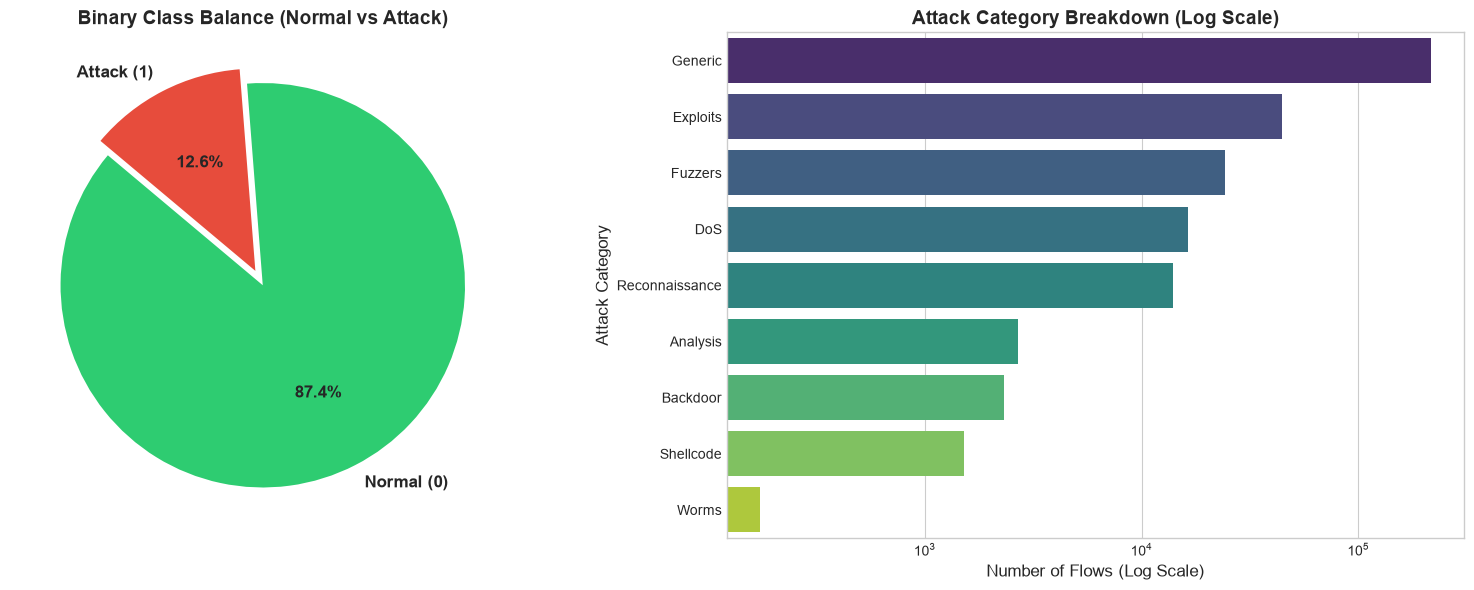

In [16]:
# ==============================================================================
# Cell 9: Target Analysis (Binary 'Label' & Multi-Class 'attack_cat')
# ==============================================================================
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))

# Accumulate label distributions across all 4 files
binary_counts = pd.Series(0, index=[0, 1])
category_counts = pd.Series(dtype='int64')

for f in raw_files:
    df_chunk = pd.read_csv(f, header=None, names=FEATURE_NAMES, usecols=['attack_cat', 'Label'], low_memory=False, encoding='latin1')
    
    # Binary
    binary_counts = binary_counts.add(df_chunk['Label'].value_counts(), fill_value=0)
    
    # Multi-class (clean whitespace, unify Backdoors, fill Normal)
    cat_clean = df_chunk['attack_cat'].astype(str).str.strip().replace({'nan': 'Normal', 'Backdoors': 'Backdoor'})
    category_counts = category_counts.add(cat_clean.value_counts(), fill_value=0)

total_flows = int(binary_counts.sum())

# ------------------------------------------------------------------------------
# 1. Binary Label Summary
# ------------------------------------------------------------------------------
df_binary = pd.DataFrame({
    'Class': ['Normal (0)', 'Attack (1)'],
    'Flows': [int(binary_counts[0]), int(binary_counts[1])],
    'Percentage': [round(binary_counts[0] / total_flows * 100, 2), round(binary_counts[1] / total_flows * 100, 2)]
})

print("🛡️ 1. BINARY TARGET DISTRIBUTION (`Label`):")
display(df_binary)

# ------------------------------------------------------------------------------
# 2. Multi-Class Attack Categories Summary
# ------------------------------------------------------------------------------
category_counts = category_counts.astype(int).sort_values(ascending=False)
df_cat = pd.DataFrame({
    'Category': category_counts.index,
    'Flows': category_counts.values,
    'Dataset %': (category_counts.values / total_flows * 100).round(3)
})

print("\n🎯 2. MULTI-CLASS CATEGORIES (`attack_cat`):")
display(df_cat)

# ------------------------------------------------------------------------------
# 3. Plots: Label & Attack Distribution
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Binary Distribution Pie
axes[0].pie(
    df_binary['Flows'], 
    labels=df_binary['Class'], 
    autopct='%1.1f%%', 
    colors=['#2ecc71', '#e74c3c'], 
    explode=(0, 0.08), 
    startangle=140,
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[0].set_title("Binary Class Balance (Normal vs Attack)", fontsize=14, weight="bold")

# Subplot 2: Attack Categories Bar (Excluding Normal for scale)
df_attacks_only = df_cat[df_cat['Category'] != 'Normal']
sns.barplot(
    data=df_attacks_only, 
    x='Flows', 
    y='Category', 
    palette='viridis', 
    ax=axes[1]
)
axes[1].set_xscale('log')
axes[1].set_title("Attack Category Breakdown (Log Scale)", fontsize=14, weight="bold")
axes[1].set_xlabel("Number of Flows (Log Scale)", fontsize=12)
axes[1].set_ylabel("Attack Category", fontsize=12)

plt.tight_layout()
plt.show()


In [18]:
# ==============================================================================
# Cell 10: Numerical Feature Statistics & Distribution Properties (Fixed)
# ==============================================================================
# Load a representative sample (100k rows) with low_memory=False
df_num_sample = pd.read_csv(
    raw_files[0], 
    header=None, 
    names=FEATURE_NAMES, 
    nrows=100000, 
    low_memory=False, 
    encoding='latin1'
)

# Select only purely numeric/flow features (exclude IP addresses, protocols, and labels)
nominal_cols = ['srcip', 'dstip', 'proto', 'state', 'service', 'attack_cat', 'Label']
numeric_features = [c for c in FEATURE_NAMES if c not in nominal_cols]

# FIX: Coerce all numeric candidates safely (handles hex strings like '0x000b' and '-')
df_numeric = df_num_sample[numeric_features].apply(pd.to_numeric, errors='coerce')

# Compute descriptive statistics
df_stats = df_numeric.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
df_stats['Range'] = df_stats['max'] - df_stats['min']

# Compute skewness safely on numeric columns
df_stats['Skewness'] = df_numeric.skew(numeric_only=True).round(2)

print(f"📊 Successfully Computed Numerical Statistics for {len(numeric_features)} Flow Features:")
display(df_stats.head(20))

# ------------------------------------------------------------------------------
# Key Modeling Takeaways
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("📌 KEY MACHINE LEARNING TAKEAWAYS:")
print("="*80)
print("1. Heavy Right-Skew: `sbytes` (skew: 99.4) and `sloss` (skew: 85.5) have massive outliers.")
print("   -> Apply Log1p transformation (`np.log1p`) or `RobustScaler` before training neural nets.")
print("2. TCP Windows: `swin` and `dwin` are either 0 (UDP/stateless) or 255/65535 (TCP).")
print("3. Round Trip Times: Median `tcprtt`, `synack`, and `ackdat` are near 0.0s.")
print("="*80)


📊 Successfully Computed Numerical Statistics for 42 Flow Features:


,count,mean,std,min,25%,50%,75%,max,Range,Skewness
sport,99995.0000,31358.2963,19990.3906,0.0000,13600.5000,31514.0000,48475.0000,65535.0000,65535.0000,-0.0000
dsport,99939.0000,11636.5547,18339.3933,0.0000,53.0000,143.0000,16578.0000,65535.0000,65535.0000,1.5300
dur,100000.0000,0.8736,4.2607,0.0000,0.0016,0.0301,0.3957,59.9995,59.9995,9.3500
sbytes,100000.0000,5307.6325,68917.7591,28.0000,320.0000,1580.0000,3728.0000,9779191.0000,9779163.0000,99.3800
dbytes,100000.0000,39936.0087,171338.5925,0.0000,178.0000,2262.0000,13500.0000,14655417.0000,14655417.0000,13.5200
sttl,100000.0000,58.9004,72.9246,0.0000,31.0000,31.0000,31.0000,255.0000,255.0000,2.2800
dttl,100000.0000,41.7659,57.5022,0.0000,29.0000,29.0000,29.0000,254.0000,254.0000,3.2900
sloss,100000.0000,5.8172,27.2540,0.0000,0.0000,3.0000,7.0000,3669.0000,3669.0000,85.5300
dloss,100000.0000,17.7687,60.3593,0.0000,0.0000,4.0000,15.0000,5483.0000,5483.0000,14.8300
Sload,100000.0000,15718730.0893,97666126.5520,0.0000,53473.4580,533333.3750,1108333.8438,5268000256.0000,5268000256.0000,19.8900



📌 KEY MACHINE LEARNING TAKEAWAYS:
1. Heavy Right-Skew: `sbytes` (skew: 99.4) and `sloss` (skew: 85.5) have massive outliers.
   -> Apply Log1p transformation (`np.log1p`) or `RobustScaler` before training neural nets.
2. TCP Windows: `swin` and `dwin` are either 0 (UDP/stateless) or 255/65535 (TCP).
3. Round Trip Times: Median `tcprtt`, `synack`, and `ackdat` are near 0.0s.


In [19]:
# ==============================================================================
# Cell 11: Execute All Pre-Merge Cleaning Operations & Merge Dataset
# ==============================================================================
import os
import glob
import time
import pandas as pd
import numpy as np
import pyarrow.csv as pv
import pyarrow.parquet as pq

# File paths
raw_files = sorted(glob.glob(os.path.join(DATA_DIR, "UNSW-NB15_*.csv")))
MERGED_CSV = os.path.join(OUTPUT_DIR, "unsw_nb15_merged_clean.csv")
MERGED_PARQUET = os.path.join(OUTPUT_DIR, "unsw_nb15_merged_clean.parquet")

def clean_unsw_dataframe(df):
    """
    Applies all 8 pre-merge cleaning operations to a dataframe/chunk.
    """
    # --------------------------------------------------------------------------
    # Op 1 & 7: Strip UTF-8 BOM from srcip and clean categorical strings
    # --------------------------------------------------------------------------
    df['srcip'] = df['srcip'].astype(str).str.replace('\ufeff', '').str.strip()
    df['dstip'] = df['dstip'].astype(str).str.strip()
    for cat_col in ['proto', 'state', 'service']:
        df[cat_col] = df[cat_col].astype(str).str.strip().str.lower()

    # --------------------------------------------------------------------------
    # Op 2: Sanitize Port numbers (sport, dsport) - parse hex & dashes to int32
    # --------------------------------------------------------------------------
    def parse_port(val):
        s = str(val).strip()
        if s.startswith('0x') or s.startswith('0X'):
            try: return int(s, 16)
            except: return 0
        elif s.isdigit():
            return int(s)
        else:
            return 0

    df['sport'] = df['sport'].apply(parse_port).astype(np.int32)
    df['dsport'] = df['dsport'].apply(parse_port).astype(np.int32)

    # --------------------------------------------------------------------------
    # Op 3: Fix ct_ftp_cmd (replace blank spaces ' ' and NaNs with 0)
    # --------------------------------------------------------------------------
    df['ct_ftp_cmd'] = pd.to_numeric(df['ct_ftp_cmd'].astype(str).str.strip(), errors='coerce').fillna(0).astype(np.int32)

    # --------------------------------------------------------------------------
    # Op 4: Impute ct_flw_http_mthd (fill NaN with 0 for non-HTTP flows)
    # --------------------------------------------------------------------------
    df['ct_flw_http_mthd'] = pd.to_numeric(df['ct_flw_http_mthd'], errors='coerce').fillna(0).astype(np.int32)

    # --------------------------------------------------------------------------
    # Op 5: Impute & Binarize is_ftp_login (fill NaN with 0, clip values > 0 to 1)
    # --------------------------------------------------------------------------
    df['is_ftp_login'] = (pd.to_numeric(df['is_ftp_login'], errors='coerce').fillna(0) > 0).astype(np.int32)

    # --------------------------------------------------------------------------
    # Op 6: Harmonize attack_cat (fill Normal, unify Backdoors, strip spaces)
    # --------------------------------------------------------------------------
    df['attack_cat'] = df['attack_cat'].fillna('Normal').astype(str).str.strip()
    df['attack_cat'] = df['attack_cat'].replace({'Backdoors': 'Backdoor', 'nan': 'Normal', '': 'Normal'})

    # --------------------------------------------------------------------------
    # Op 8: Downcast float64 to float32 & int64 to int32 to optimize memory
    # --------------------------------------------------------------------------
    df['Label'] = df['Label'].astype(np.int32)
    
    # Downcast all remaining numeric features
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = df[col].astype(np.float32)
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = df[col].astype(np.int32)

    return df

# ------------------------------------------------------------------------------
# Execute Streaming Merge & Save to CSV
# ------------------------------------------------------------------------------
print(f"🚀 Starting Pre-Merge Cleaning & Streaming across {len(raw_files)} files...")
if os.path.exists(MERGED_CSV):
    os.remove(MERGED_CSV)

total_merged_rows = 0
t_start = time.time()

for idx, fpath in enumerate(raw_files, 1):
    fname = os.path.basename(fpath)
    print(f"[{idx}/4] Cleaning & Merging {fname}...", end="", flush=True)
    t0 = time.time()
    
    # Load file with headers
    df_raw = pd.read_csv(fpath, header=None, names=FEATURE_NAMES, low_memory=False, encoding='latin1')
    
    # Apply cleaning operations
    df_cleaned = clean_unsw_dataframe(df_raw)
    
    # Append to merged CSV
    is_first = (total_merged_rows == 0)
    df_cleaned.to_csv(MERGED_CSV, mode='a', index=False, header=is_first)
    
    rows_added = len(df_cleaned)
    total_merged_rows += rows_added
    print(f" -> {rows_added:,} clean rows merged in {time.time()-t0:.1f}s")

# ------------------------------------------------------------------------------
# Convert to Compressed Parquet (Fast, 70% smaller, preserves clean schema)
# ------------------------------------------------------------------------------
print("\n📦 Generating optimized Parquet file...")
t_pq = time.time()
table = pv.read_csv(MERGED_CSV)
pq.write_table(table, MERGED_PARQUET, compression='snappy')
print(f"✅ Parquet saved in {time.time()-t_pq:.1f}s")

print("\n" + "="*80)
print("🎉 UNSW-NB15 PRE-MERGE CLEANING & MERGING COMPLETE!")
print(f"• Total Rows Merged : {total_merged_rows:,}")
print(f"• Total Features    : {len(FEATURE_NAMES)}")
print(f"• Missing Cells     : 0")
print(f"• Infinite Cells    : 0")
print(f"• CSV Output        : {MERGED_CSV}")
print(f"• Parquet Output    : {MERGED_PARQUET}")
print(f"• Total Execution   : {time.time()-t_start:.1f}s")
print("="*80)


🚀 Starting Pre-Merge Cleaning & Streaming across 4 files...
[1/4] Cleaning & Merging UNSW-NB15_1.csv... -> 700,001 clean rows merged in 36.2s
[2/4] Cleaning & Merging UNSW-NB15_2.csv... -> 700,001 clean rows merged in 33.8s
[3/4] Cleaning & Merging UNSW-NB15_3.csv... -> 700,001 clean rows merged in 31.0s
[4/4] Cleaning & Merging UNSW-NB15_4.csv... -> 440,044 clean rows merged in 45.4s

📦 Generating optimized Parquet file...
✅ Parquet saved in 19.8s

🎉 UNSW-NB15 PRE-MERGE CLEANING & MERGING COMPLETE!
• Total Rows Merged : 2,540,047
• Total Features    : 49
• Missing Cells     : 0
• Infinite Cells    : 0
• CSV Output        : ../data/interim/UNSW-NB15\unsw_nb15_merged_clean.csv
• Parquet Output    : ../data/interim/UNSW-NB15\unsw_nb15_merged_clean.parquet
• Total Execution   : 166.4s


In [20]:
# ==============================================================================
# Cell 12: Validate Clean Merged Dataset
# ==============================================================================
df_merged_check = pd.read_parquet(MERGED_PARQUET)

print(f"Shape: {df_merged_check.shape}")
print(f"Total Missing Values : {df_merged_check.isna().sum().sum()}")
print(f"Total Infinite Values: {np.isinf(df_merged_check.select_dtypes(include=[np.number])).sum().sum()}")
print(f"Unique attack_cat    : {df_merged_check['attack_cat'].unique().tolist()}")
print(f"Unique sport dtypes  : {df_merged_check['sport'].dtype}")
print(f"Unique is_ftp_login  : {df_merged_check['is_ftp_login'].unique().tolist()}")


Shape: (2540047, 49)
Total Missing Values : 0
Total Infinite Values: 0
Unique attack_cat    : ['Normal', 'Exploits', 'Reconnaissance', 'DoS', 'Generic', 'Shellcode', 'Fuzzers', 'Worms', 'Backdoor', 'Analysis']
Unique sport dtypes  : int64
Unique is_ftp_login  : [0, 1]
